In [1]:
library(Seurat)
library(stringr)
library(ggplot2)
library(ggpubr)
library(viridis)
library(rtracklayer)
library(GenomicRanges)
library(Signac)
library(AnnotationHub)
library(reshape2)
library(GenomicRanges)
library(BSgenome.Hsapiens.UCSC.hg38)
library(BSgenome)
library(patchwork)
library(ggrastr)
library(cowplot)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Loading required package: viridisLite

Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:SeuratObject’:

    intersect


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading 

## Loading and processing the 10X Transcriptome data
First, reading in the raw data. The following function loads in a specified 10X lane, and adds the T7 association data:

In [2]:
load_data <- function(rep) {
    obj.path <- paste0("./count_RNA/t7_filtered_counts/t7-filtered_RNA_",rep, 
                       "/outs/filtered_feature_bc_matrix")
    K562_L.data <- Read10X(data.dir = obj.path)
    K562_L <- CreateSeuratObject(counts = K562_L.data, project = rep)
    K562_L@meta.data$cbc <- rownames(K562_L@meta.data)

    t7.path <- paste0("./t7_K562_",rep,".associations.tsv")
    t7_counts <- read.table(t7.path,header=TRUE)
    t7_counts <- t7_counts[t7_counts$umis >= 10 & t7_counts$reads >= 10,]
    
    collapsed <- tapply(t7_counts$location_barcode,
                    INDEX = t7_counts$cbc,
                    FUN = function(x) paste(unique(x), collapse = "_"))

    K562_L@meta.data$location_barcode <- collapsed[
      match(K562_L@meta.data$cbc, names(collapsed))
    ]

    K562_L@meta.data$location_barcode[is.na(K562_L@meta.data$location_barcode) == TRUE] <- ""
    K562_L
    }

Reading in each 10X lane and merging them into a single object. Also adding a meta data column indicating the percent mitochondrial reads:

In [3]:
K562_L1 <- load_data("L1")
K562_L2 <- load_data("L2")

obj <- merge(K562_L1, y = K562_L2, add.cell.ids = c("L1", "L2"), project = "K562_T7")
obj[["percent.mt"]] <- PercentageFeatureSet(obj, pattern = "^MT-")

### Visualizing QC stats before filtering out low quality cells
Visualizing the distribution of UMIs, gene counts, and mitochondrial read percentage

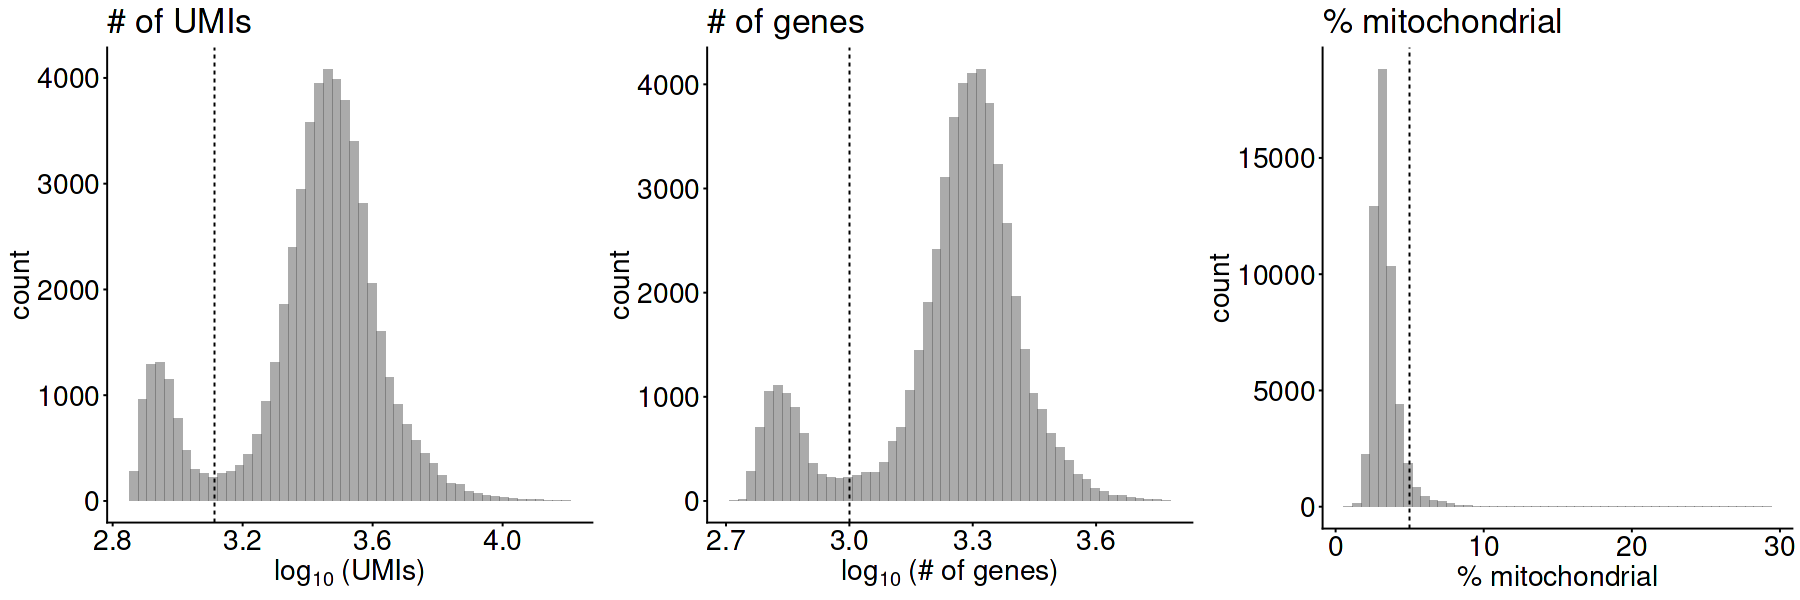

In [4]:
a <- ggplot(obj@meta.data,aes(x=log10(nCount_RNA))) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        axis.text  = element_text(size = 20),
        axis.title = element_text(size = 20),
        plot.title = element_text(size = 24),
        legend.position = "none") + 
  xlab(bquote(log[10]~"(UMIs)")) + 
  geom_vline(xintercept=log10(1300),linetype="dashed") + 
  ggtitle("# of UMIs")

b <- ggplot(obj@meta.data,aes(x=log10(nFeature_RNA))) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        axis.text  = element_text(size = 20),
        axis.title = element_text(size = 20),
        plot.title = element_text(size = 24),
        legend.position = "none") + 
  xlab(bquote(log[10]~"(# of genes)")) + 
  geom_vline(xintercept=log10(1000),linetype="dashed")+ 
  ggtitle("# of genes")

c <- ggplot(obj@meta.data,aes(x=percent.mt)) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        axis.text  = element_text(size = 20),
        axis.title = element_text(size = 20),
        plot.title = element_text(size = 24),
        legend.position = "none") + 
  xlab("% mitochondrial") + 
  geom_vline(xintercept=5,linetype="dashed")+ 
  ggtitle("% mitochondrial")

options(repr.plot.width = 18, repr.plot.height = 6, repr.plot.res = 100)
ggarrange(a,b,c, ncol=3, nrow=1)

### Filtering out low quality cells and visualizing QC stats again after filtering
Removing cells with fewer than 300 UMIs + genes, as well as cells with 5% or more mitochondrial reads

In [5]:
obj <- subset(obj, subset = nFeature_RNA > 1000 & nCount_RNA > 1300 & percent.mt < 5)

Re-visualizing QC metrics after filtering:

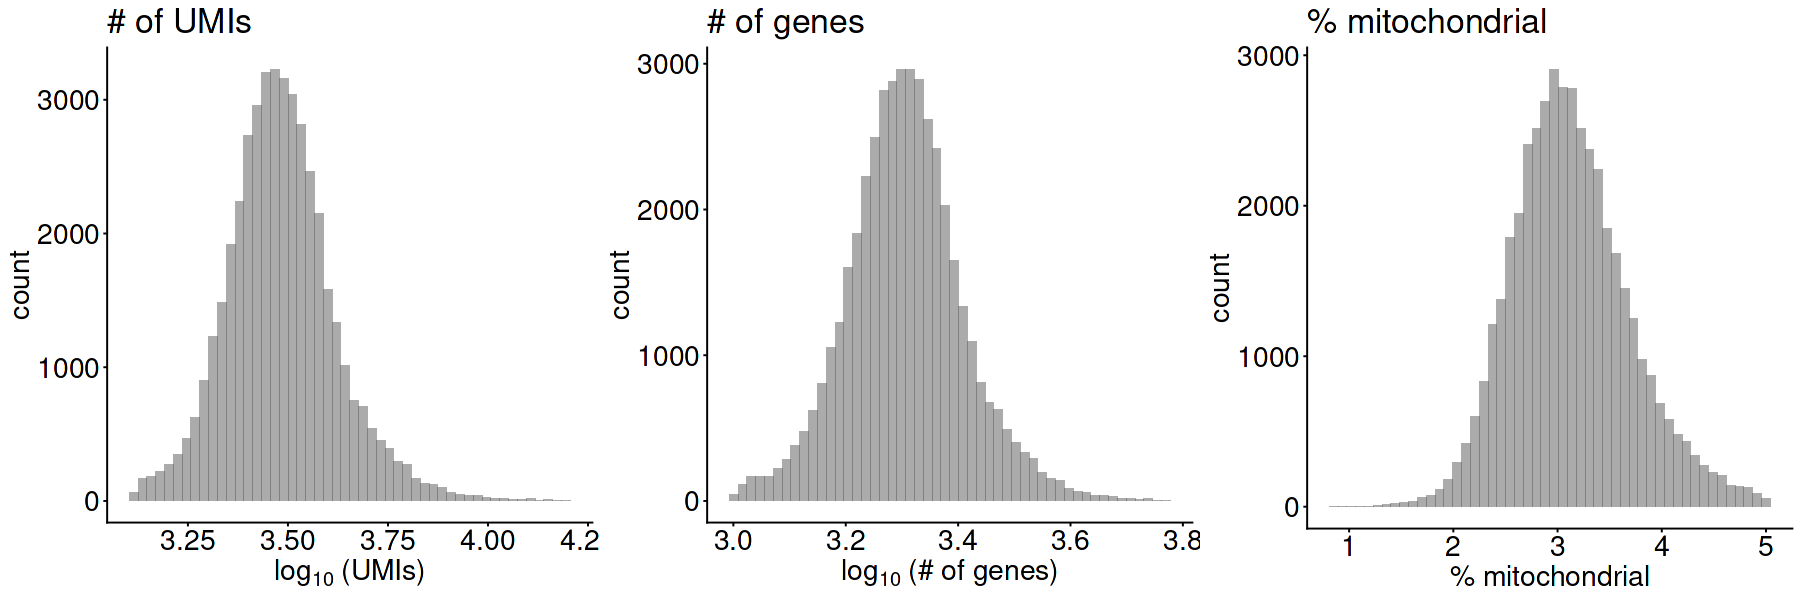

In [6]:
a <- ggplot(obj@meta.data,aes(x=log10(nCount_RNA))) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        axis.text  = element_text(size = 20),
        axis.title = element_text(size = 20),
        plot.title = element_text(size = 24),
        legend.position = "none") + 
  xlab(bquote(log[10]~"(UMIs)")) + 
  ggtitle("# of UMIs")

b <- ggplot(obj@meta.data,aes(x=log10(nFeature_RNA))) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        axis.text  = element_text(size = 20),
        axis.title = element_text(size = 20),
        plot.title = element_text(size = 24),
        legend.position = "none") + 
  xlab(bquote(log[10]~"(# of genes)")) + 
  ggtitle("# of genes")

c <- ggplot(obj@meta.data,aes(x=percent.mt)) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        axis.text  = element_text(size = 20),
        axis.title = element_text(size = 20),
        plot.title = element_text(size = 24),
        legend.position = "none") + 
  xlab("% mitochondrial") +
  ggtitle("% mitochondrial")

options(repr.plot.width = 18, repr.plot.height = 6, repr.plot.res = 100)
ggarrange(a,b,c, ncol=3, nrow=1)

### Data normalization and dimensionality reduction
Running standard Seurat data normalization and dimensionality reduction functions:

In [7]:
DefaultAssay(obj) <- "RNA" 
obj <- JoinLayers(obj)

obj <- NormalizeData(obj, verbose = FALSE)
obj <- FindVariableFeatures(obj, selection.method = "vst", nfeatures = 2000, verbose = FALSE)

obj <- ScaleData(obj, features = VariableFeatures(obj),
                 vars.to.regress = c("nCount_RNA"),
                 verbose = FALSE)

obj <- RunPCA(obj, features = VariableFeatures(obj), verbose = FALSE)

obj <- FindNeighbors(obj, dims = 1:10)
obj <- FindClusters(obj, resolution = 0.5)

set.seed(1234)
obj <- RunUMAP(obj, dims = 1:10)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 44077
Number of edges: 975389

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7791
Number of communities: 9
Elapsed time: 14 seconds


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
05:51:47 UMAP embedding parameters a = 0.9922 b = 1.112

05:51:47 Read 44077 rows and found 10 numeric columns

05:51:47 Using Annoy for neighbor search, n_neighbors = 30

05:51:47 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

05:51:51 Writing NN index file to temp file /tmp/532694.1.shendure-login.q/RtmpHCBtjO/file3993b23484bad1

05:51:51 Searching Annoy index using 1 thread, search_k = 3000

05:52:11 Annoy recall = 100%

05:52:11 Commencing smooth kNN distance calibration using 1 thre

### Adding additional deletion meta data
Reading in a dataframe called "pELS.gRNAs" that contains information on the CREs that were targeted (e.g. genomic coordinates, spacers used, etc.) as well as a dataframe with the ordered oligo sequences called "oligos":

In [2]:
pELS.gRNAs <- read.csv("gRNA-pairs_K562-intronic-pELS.csv", header = TRUE, stringsAsFactors = FALSE)

pELS.gRNAs <- pELS.gRNAs[,c("g1_ccre_id","g1_cre_loc",
                            "g1_synthesis_sequence","g1_cutting_efficiency","g1_specificity",
                            "g2_synthesis_sequence","g2_cutting_efficiency","g2_specificity",
                              "g1_grna_start","g2_grna_start")]


colnames(pELS.gRNAs) <- c("CRE","peak","spacer1","spacer1_efficiency","spacer1_specificity",
                                       "spacer2","spacer2_efficiency","spacer2_specificity",
                                          "spacer1_start","spacer2_start")

pELS.gRNAs$both_spacers <- paste0(pELS.gRNAs$spacer1,"_",pELS.gRNAs$spacer2)

Next, reading in a dataframe that has a mapping from my bulk T7 data / analysis that shows for each location_barcode, which CRE it is overlapping/targeting:

In [3]:
location_mapping <- read.csv("location-barcode_CRE.tsv", header = TRUE, sep = "\t")
location_mapping$CRE <- pELS.gRNAs$CRE[match(location_mapping$overlapping_CRE,pELS.gRNAs$peak)]
head(location_mapping)

,location_barcode,overlapping_CRE,CRE
,<chr>,<chr>,<chr>
1,chr1-113930432-AAGTGCT,chr1-113930138-113930484,EH38D4412847
2,chr1-113930384-AGTCCAT,chr1-113930138-113930484,EH38D4412847
3,chr1-113930432-CACTGTT,chr1-113930138-113930484,EH38D4412847
4,chr1-113930384-CGAAGTG,chr1-113930138-113930484,EH38D4412847
5,chr1-113930432-CTGACGA,chr1-113930138-113930484,EH38D4412847
6,chr1-113930384-GTGGCGG,chr1-113930138-113930484,EH38D4412847


Adding the mappings to the object meta data:

In [10]:
## 0) Ensure character
obj@meta.data$location_barcode <- as.character(obj@meta.data$location_barcode)
location_mapping$location_barcode <- as.character(location_mapping$location_barcode)
location_mapping$overlapping_CRE  <- as.character(location_mapping$overlapping_CRE)
location_mapping$CRE              <- as.character(location_mapping$CRE)

## 1) Build named lookup vectors: barcode -> CRE, barcode -> CRE_id
map_CRE    <- setNames(location_mapping$overlapping_CRE, location_mapping$location_barcode)
map_CRE_id <- setNames(location_mapping$CRE,              location_mapping$location_barcode)

## 2) Split per-cell barcode strings into vectors
lb_list <- strsplit(obj@meta.data$location_barcode, "_", fixed = TRUE)

## 3) Helper to map + collapse (dedupe, handle NA/empty)
collapse_map <- function(vals, map_vec) {
  if (length(vals) == 0L) return("")
  vals <- vals[nzchar(vals)]                   # drop empty pieces
  if (length(vals) == 0L) return("")
  out <- unname(map_vec[vals])                 # lookup
  out <- unique(out[!is.na(out) & nzchar(out)])# dedupe & drop NAs/empties
  if (length(out) == 0L) "" else paste(out, collapse = "_")
}

## 4) Apply for CRE and CRE_id
obj@meta.data$CRE    <- vapply(lb_list, collapse_map, character(1), map_vec = map_CRE)
obj@meta.data$CRE_id <- vapply(lb_list, collapse_map, character(1), map_vec = map_CRE_id)

Similarly, need to add mapping information that says which CRE overlaps an intron for which genes:

In [22]:
CRE_genes <- read.table("CRE_gene_mapping.tsv",header=TRUE)

## Build a named lookup: CRE → gene_name
map_genes <- setNames(CRE_genes$gene_name, CRE_genes$CRE)

## Split cell CRE strings
cre_list <- strsplit(obj@meta.data$CRE, "_", fixed = TRUE)

## Helper to look up and collapse gene names
collapse_genes <- function(vals, map_vec) {
  if (length(vals) == 0L) return("")
  vals <- vals[nzchar(vals)]                       # drop empties
  if (length(vals) == 0L) return("")
  out <- unname(map_vec[vals])                     # look up
  out <- unique(out[!is.na(out) & nzchar(out)])    # dedupe & drop NAs
  if (length(out) == 0L) "" else paste(out, collapse = "_")
}

## Apply to each cell
obj@meta.data$CRE_gene <- vapply(cre_list, collapse_genes, character(1), map_vec = map_genes)

In [14]:
saveRDS(obj,file="./t7-filtered.K562-L1-L2.normalized-obj.rds")

In [2]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.4 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] cowplot_1.2.0                     ggrastr_1.0.2                    
 [3] patchwork_1.3.2                   BSgenome.Hsapiens.UCSC.hg38_1.4.5
 